# <center>**Chapter 27 - LSTM for Time Series Prediction in PyTorch**<center>

**Mục tiêu:** Hiểu cấu trúc LSTM, xây dựng mô hình dự đoán số hành khách hàng tháng, đánh giá mô hình trên tập train/test bằng RMSE và quan sát dự đoán theo từng lookback.

**Phương pháp:** Đọc dữ liệu airline-passengers, chia dữ liệu theo thứ tự thời gian (67% train - 33% test), tạo cửa sổ trượt, huấn luyện LSTM 1 tầng bằng MSE + Adam, sau đó trích trạng thái cuối để dự đoán bước kế tiếp.

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

plt.style.use("seaborn-v0_8-darkgrid")
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị:", device)

Thiết bị: cpu


## **1. Khám phá dữ liệu chuỗi thời gian**

Dữ liệu chỉ có một đặc trưng là số hành khách. Đồ thị cho thấy xu hướng tăng và tính mùa vụ; theo PDF, ví dụ này không loại trend hay chuẩn hóa để tập trung vào kiến trúc LSTM.

In [8]:
data_path = os.path.join("data", "airline-passengers.csv")
df = pd.read_csv(data_path)
print(df.head())
print("Số quan sát:", len(df))

     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121
Số quan sát: 144


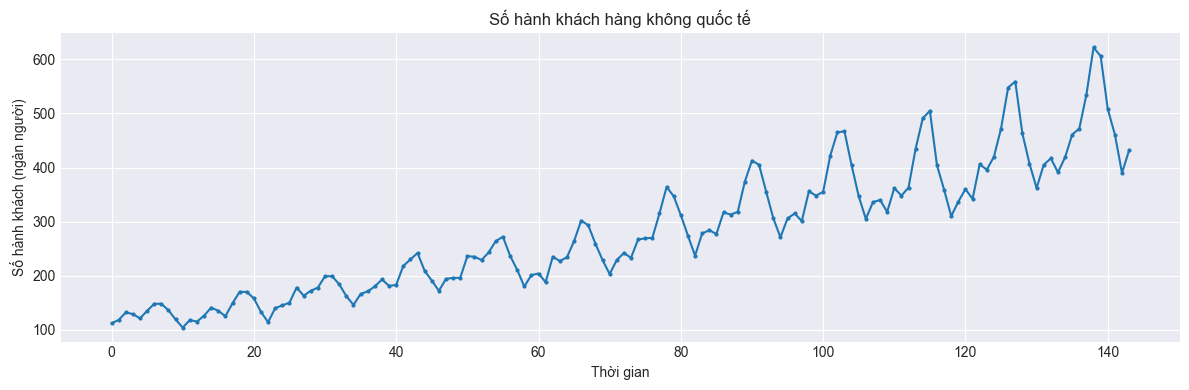

In [9]:
timeseries = df[["Passengers"]].values.astype("float32")
plt.figure(figsize=(12, 4))
plt.plot(timeseries, marker="o", markersize=2)
plt.title("Số hành khách hàng không quốc tế")
plt.xlabel("Thời gian")
plt.ylabel("Số hành khách (ngàn người)")
plt.tight_layout()
plt.show()

## **2. Chia train/test và tạo cửa sổ dự đoán**

Không xáo trộn dữ liệu vì thứ tự thời gian phải được bảo toàn. Hàm `create_dataset` chuyển mỗi cửa sổ `lookback` thành tensor dạng `(batch, time steps, features)`.

In [10]:
train_size = int(len(timeseries) * 0.67)
train = timeseries[:train_size]
test = timeseries[train_size:]
print("Train:", len(train), "| Test:", len(test))

def create_dataset(dataset, lookback):
    # Tạo cặp cửa sổ đầu vào và chuỗi nhãn dịch chuyển một bước
    X, y = [], []
    for i in range(len(dataset) - lookback):
        X.append(dataset[i:i + lookback])
        y.append(dataset[i + 1:i + lookback + 1])
    return torch.tensor(np.asarray(X), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.float32)

lookback = 4
X_train, y_train = create_dataset(train, lookback)
X_test, y_test = create_dataset(test, lookback)

print("Kích thước X_train:", tuple(X_train.shape))
print("Kích thước y_train:", tuple(y_train.shape))
print("Kích thước X_test:", tuple(X_test.shape))

Train: 96 | Test: 48
Kích thước X_train: (92, 4, 1)
Kích thước y_train: (92, 4, 1)
Kích thước X_test: (44, 4, 1)


## **3. Xây dựng mô hình LSTM**

LSTM đọc 4 bước quan sát gần nhất; lớp `Linear` ánh xạ trạng thái ẩn cuối thành một giá trị hồi quy. Chỉ lấy đầu ra tại timestep cuối để dự đoán.

In [11]:
class AirModel(nn.Module):
    def __init__(self, hidden_size=50):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size,
                            num_layers=1, batch_first=True)
        self.linear = nn.Linear(hidden_size, 1)

    def forward(self, x):
        hidden_states, _ = self.lstm(x)
        # Chỉ trạng thái cuối cùng được dùng cho dự đoán bước kế tiếp.
        last_state = hidden_states[:, -1, :]
        return self.linear(last_state)

model = AirModel().to(device)
print(model)

AirModel(
  (lstm): LSTM(1, 50, batch_first=True)
  (linear): Linear(in_features=50, out_features=1, bias=True)
)


## **4. Huấn luyện và theo dõi RMSE**

MSE được dùng cho bài toán hồi quy và Adam tối ưu tham số. Mô hình chạy 600 epoch; kết quả theo dõi tại mỗi 50 epoch cho thấy RMSE giảm liên tục. Tại epoch 550, Train RMSE là 56.8006 và Test RMSE là 219.4698.

In [12]:
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
loader = data.DataLoader(data.TensorDataset(X_train, y_train),
                         shuffle=True, batch_size=8)

n_epochs = 600
history = []
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch[:, -1, :].to(device)
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch % 50 == 0:
        model.eval()
        with torch.no_grad():
            train_pred = model(X_train.to(device)).cpu().numpy()
            test_pred = model(X_test.to(device)).cpu().numpy()
            train_rmse = np.sqrt(np.mean((train_pred - y_train[:, -1].numpy()) ** 2))
            test_rmse = np.sqrt(np.mean((test_pred - y_test[:, -1].numpy()) ** 2))
        history.append((epoch, train_rmse, test_rmse))
        print(f"Epoch {epoch:4d}: train RMSE {train_rmse:.4f}, test RMSE {test_rmse:.4f}")

Epoch    0: train RMSE 229.0622, test RMSE 428.2633
Epoch   50: train RMSE 202.2038, test RMSE 400.3074
Epoch  100: train RMSE 180.9487, test RMSE 377.8907
Epoch  150: train RMSE 161.5494, test RMSE 357.0650
Epoch  200: train RMSE 143.7912, test RMSE 337.5285
Epoch  250: train RMSE 127.5269, test RMSE 319.0039
Epoch  300: train RMSE 112.9699, test RMSE 301.5702
Epoch  350: train RMSE 100.3307, test RMSE 285.2779
Epoch  400: train RMSE 89.2582, test RMSE 270.2047
Epoch  450: train RMSE 75.1868, test RMSE 250.2514
Epoch  500: train RMSE 65.0011, test RMSE 233.9919
Epoch  550: train RMSE 56.8006, test RMSE 219.4698


## **5. Trực quan hóa dự đoán**

Các điểm dự đoán được đưa về đúng vị trí thời gian tương ứng. Đường xanh lá biểu diễn dự đoán trên test set sau ranh giới train/test. Do biểu đồ cũng phản ánh sai số test còn lớn, mô hình phù hợp với xu hướng train tốt hơn, nhưng vẫn chưa bắt trọn trend/mùa vụ ngoài tập train.

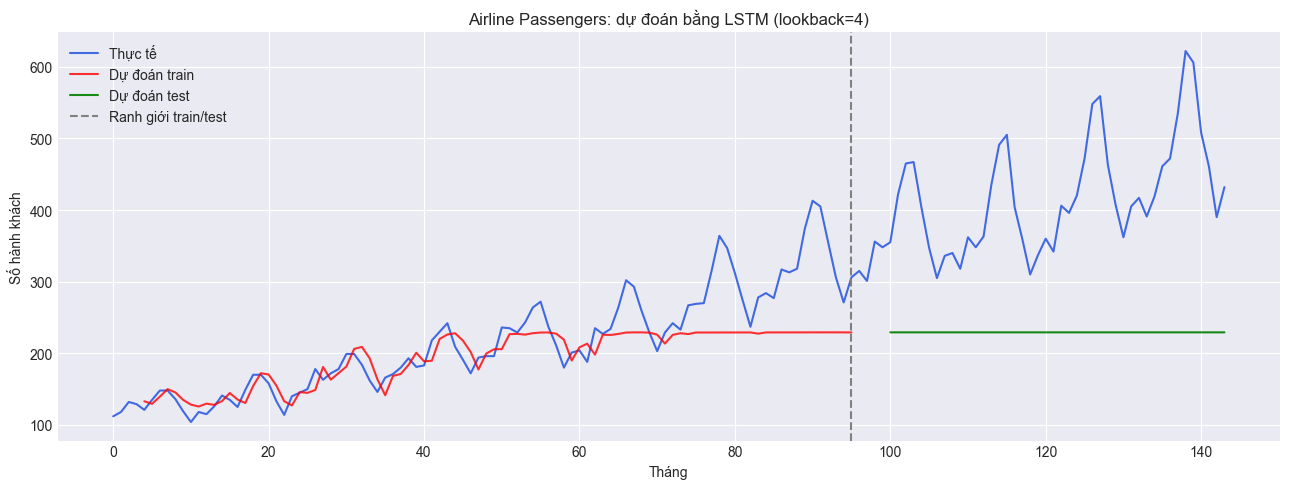

In [13]:
model.eval()
with torch.no_grad():
    train_pred = model(X_train.to(device)).cpu().numpy().flatten()
    test_pred = model(X_test.to(device)).cpu().numpy().flatten()

train_plot = np.full(len(timeseries), np.nan)
test_plot = np.full(len(timeseries), np.nan)
train_plot[lookback:train_size] = train_pred
test_plot[train_size + lookback:len(timeseries)] = test_pred

plt.figure(figsize=(13, 5))
plt.plot(timeseries, label="Thực tế", color="royalblue")
plt.plot(train_plot, label="Dự đoán train", color="red", alpha=0.8)
plt.plot(test_plot, label="Dự đoán test", color="green", alpha=0.9)
plt.axvline(train_size - 1, color="gray", linestyle="--", label="Ranh giới train/test")
plt.title("Airline Passengers: dự đoán bằng LSTM (lookback=4)")
plt.xlabel("Tháng")
plt.ylabel("Số hành khách")
plt.legend()
plt.tight_layout()
plt.show()

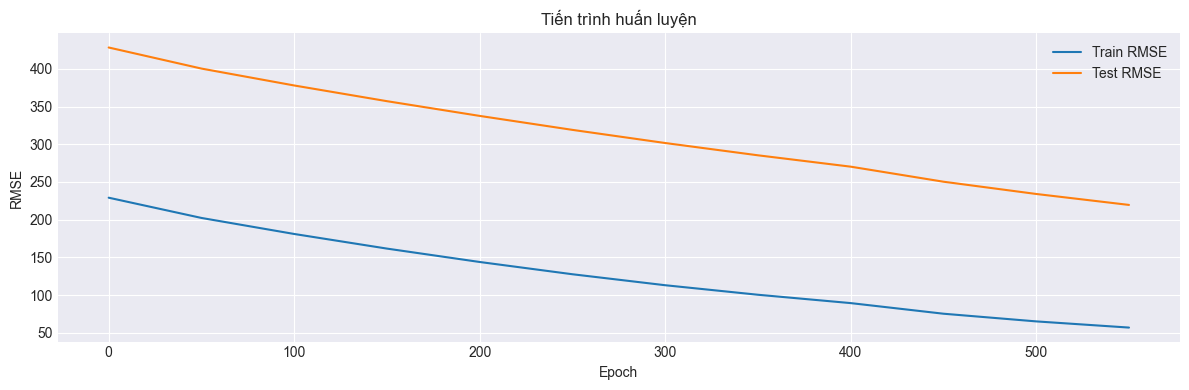

In [14]:
# Tiến trình huấn luyện
epochs = [row[0] for row in history]
train_rmse = [row[1] for row in history]
test_rmse = [row[2] for row in history]

plt.figure(figsize=(12, 4))
plt.plot(epochs, train_rmse, label="Train RMSE")
plt.plot(epochs, test_rmse, label="Test RMSE")
plt.title("Tiến trình huấn luyện")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.tight_layout()
plt.show()

## **Kết luận**

- Với lookback = 4, mô hình LSTM đã giảm Train RMSE từ 229.0622 ở epoch 0 xuống 56.8006 ở epoch 550.
- Test RMSE cũng giảm từ 428.2633 xuống 219.4698, chứng tỏ mô hình học được xu hướng chung nhưng sai số test vẫn lớn hơn nhiều so với train.
- Đây là kết quả hợp lý với dữ liệu thô chưa detrend/chuẩn hóa và có tính mùa vụ. Việc chuẩn hóa dữ liệu hoặc dùng cửa sổ/lookback khác có thể cải thiện độ ổn định.
- Quy trình bám sát PDF: giữ thứ tự dữ liệu theo thời gian, tạo cửa sổ trượt, dùng MSE + Adam và lấy hidden state cuối của LSTM để dự đoán.

# <center>**HẾT**<center>